# Домашнее задание 1. Рекомендации треков на Yambda-50M

Я рекомендую **треки**. Положительным событием считаю `Listen+`: пользователь прослушал больше 50% трека. Так же определяется положительное прослушивание в [описании Yambda](https://huggingface.co/datasets/yandex/yambda). Это наблюдаемый признак интереса, а не доказательство, что музыка понравилась.

Источник — [Yambda](https://huggingface.co/datasets/yandex/yambda), статья авторов — [Yambda-5B](https://arxiv.org/html/2505.22238). Я использую Yambda-50M, фиксирую ревизию данных, выбор пользователей и временные границы. Аудиоэмбеддинги не скачиваю.

Перед экспериментом ожидаю следующее: EASE сумеет использовать связи между треками лучше простого списка популярных; метаданные артиста и альбома дадут FM полезный дополнительный сигнал; градуированный таргет для ALS может улучшить бинарный. Проверю это на одном наборе будущих прослушиваний.

## 1. Подготовка данных

Выполнять ячейки нужно сверху вниз. При первом запуске загрузятся три исходных файла: события Yambda-50M и две таблицы связей треков с исполнителями и альбомами. Подготовленная выборка сохранится **локально** в папке `data/`; файлы данных в репозиторий не входят. Если переменная окружения `YAMBDA_WORK_DIR` задана, использую эту папку вместо `data/`.

In [1]:
from pathlib import Path
import os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")
PROJECT = next(p for p in [Path.cwd(), Path.cwd() / "outputs/yambda_homework"]
               if (p / "data_pipeline.py").exists())
sys.path.insert(0, str(PROJECT))
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
from data_pipeline import prepare, load_prepared, REPO_ID, REVISION, SEED
from evaluation import index_events, training_matrices, future_truth, rank_and_evaluate
from experiment_utils import search, chosen_config, fit_and_predict

In [2]:
info = prepare()
events, metadata = load_prepared(info)
display(pd.DataFrame({
    "показатель": ["исходные события", "исходные пользователи", "исходные треки",
                   "итоговые события", "итоговые пользователи", "итоговые треки"],
    "значение": [47_790_449, info["source_users"], 934_057,
                 len(events), events.uid.nunique(), events.item_id.nunique()],
}))

,показатель,значение
0,исходные события,47790449
1,исходные пользователи,10000
2,исходные треки,934057
3,итоговые события,1334596
4,итоговые пользователи,1479
5,итоговые треки,3000


Yambda-50M содержит 47 790 449 событий 10 000 пользователей по 934 057 трекам. Для моей выборки я случайно взяла 15% пользователей с `seed=42`, затем последние 150 дней и 3000 треков с наибольшим числом разных пользователей с `Listen+` **в train**. При равенстве использовала число положительных событий и ID трека. Точные дубликаты строк удалены. В итоге осталось **1 334 596 событий, 1479 пользователей и 3000 треков**: лимиты задания соблюдены. Отбор по популярности делает задачу вычислимой для EASE, но ограничивает выводы популярной частью каталога.

Поля событий: `uid` — ID пользователя, `item_id` — ID трека, `timestamp` — относительное время с точностью до 5 секунд, `is_organic` — самостоятельное обнаружение или путь через рекомендацию, `event_type` — тип действия. `played_ratio_pct` — процент прослушанного, `track_length_seconds` — длина трека; эти два поля есть только у `listen`. Их значение нельзя подать модели для **будущего** события. `like` и `dislike` — явные реакции, `unlike` и `undislike` их отменяют.

In [3]:
schema = pd.DataFrame({
    "тип": events.dtypes.astype(str),
    "пропусков": events.isna().sum(),
    "доля_пропусков": events.isna().mean().round(4),
})
display(schema)
display(events.event_type.value_counts().rename_axis("тип события").to_frame("число событий"))

,тип,пропусков,доля_пропусков
uid,uint32,0,0.00
timestamp,uint32,0,0.00
item_id,uint32,0,0.00
is_organic,uint8,0,0.00
played_ratio_pct,UInt16,26652,0.02
track_length_seconds,UInt32,26652,0.02
event_type,category,0,0.00


,число событий
тип события,
listen,1307944
like,21326
unlike,3089
dislike,1992
undislike,245


Пропуски есть только в проценте прослушанного и длине трека — **26 652 строки**, ровно столько же, сколько событий не типа `listen`. Это свойство схемы, а не повод заполнять долю прослушивания нулём для лайков. В данных после отбора 1 307 944 прослушивания; лайков 21 326, дизлайков 1992. Из-за такого дисбаланса основной критерий я строю по прослушиваниям, а реакции использую в отдельном эксперименте с таргетом.

In [4]:
db = duckdb.connect()
raw_slice = db.execute('''
    SELECT COUNT(*) AS before_dedup,
           COUNT(DISTINCT (uid,item_id,"timestamp",event_type,
                           played_ratio_pct,track_length_seconds,is_organic)) AS after_dedup
    FROM read_parquet(?) c SEMI JOIN read_parquet(?) m USING(item_id)
    WHERE c."timestamp">=? AND c."timestamp"<=?
''', [info["cohort_file"], info["metadata_file"],
       info["t_start"], info["t_finish"]]).df()
display(raw_slice)

,before_dedup,after_dedup
0,1340569,1334596


В выбранном временном окне и каталоге было **1 340 569** строк. Среди них **5973 точных повторов** по всем полям; после удаления осталось 1 334 596. Одинаковые действия с разным временем я оставила: это может быть реальное повторное прослушивание. Время округлено до пяти секунд, поэтому даже точные повторы нельзя на сто процентов отделить от повторной записи события — это ограничение очистки.

## 2. EDA

Посмотрю активность пользователей, популярность треков, разреженность и доступные метапризнаки. Для графиков использую уже выбранный каталог; они описывают именно эту выборку, а не всю Yambda.

In [5]:
user_activity = events.groupby("uid").size()
positive_listens = events[(events.event_type == "listen") & (events.played_ratio_pct > 50)]
item_activity = positive_listens.groupby("item_id").uid.nunique()
display(pd.DataFrame({
    "показатель": ["мин", "медиана", "90-й процентиль", "макс"],
    "событий у пользователя": [user_activity.min(), user_activity.median(),
                                user_activity.quantile(.9), user_activity.max()],
    "слушателей у трека": [item_activity.min(), item_activity.median(),
                            item_activity.quantile(.9), item_activity.max()],
}))

,показатель,событий у пользователя,слушателей у трека
0,мин,1.0,36.0
1,медиана,483.0,72.0
2,90-й процентиль,2369.0,155.1
3,макс,11577.0,595.0


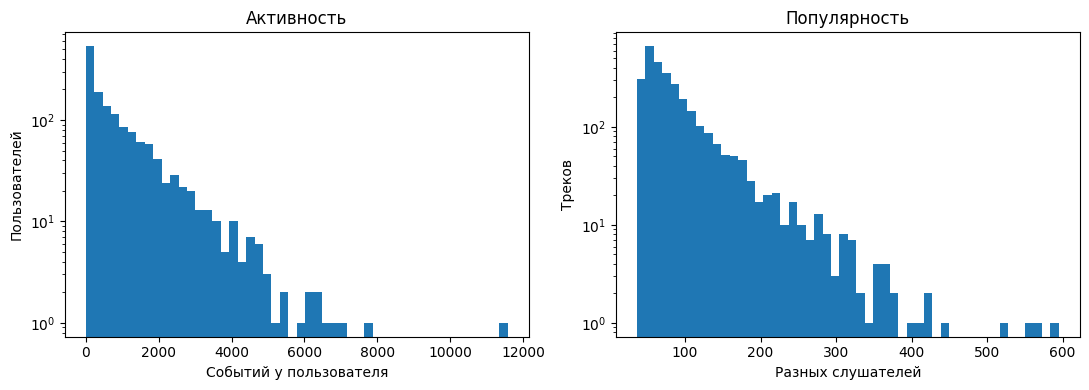

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(user_activity, bins=50)
axes[0].set(xlabel="Событий у пользователя", ylabel="Пользователей", title="Активность")
axes[1].hist(item_activity, bins=50)
axes[1].set(xlabel="Разных слушателей", ylabel="Треков", title="Популярность")
for ax in axes: ax.set_yscale("log")
plt.tight_layout()
plt.show()

У медианного пользователя **483 события**, но максимум — **11 577**; у трека медиана — **72 разных положительных слушателя**, максимум — **595**. Поэтому простой счётчик событий дал бы активным пользователям большой вес. Каталог уже отобран по популярности на train: минимум 36 слушателей здесь нельзя переносить на весь исходный датасет. На графиках виден разброс даже внутри популярной части каталога.

In [7]:
display(metadata[["n_artists", "n_albums"]].describe().T)
display(pd.DataFrame({
    "признак": ["artist_id", "album_id", "треков с несколькими альбомами"],
    "число треков": [metadata.artist_id.notna().sum(),
                      metadata.album_id.notna().sum(), (metadata.n_albums > 1).sum()],
}))

,count,mean,std,min,25%,50%,75%,max
n_artists,3000.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
n_albums,3000.0,4.529667,13.171976,1.0,1.0,2.0,3.0,241.0


,признак,число треков
0,artist_id,3000
1,album_id,3000
2,треков с несколькими альбомами,1514


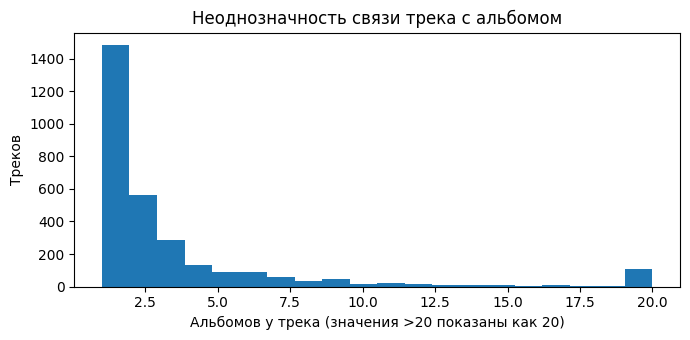

In [8]:
plt.figure(figsize=(7, 3.5))
plt.hist(metadata.n_albums.clip(upper=20), bins=20)
plt.xlabel("Альбомов у трека (значения >20 показаны как 20)")
plt.ylabel("Треков")
plt.title("Неоднозначность связи трека с альбомом")
plt.tight_layout()
plt.show()

У всех 3000 треков есть ID исполнителя и альбома; у **1514 треков альбомов несколько**, максимум **241**. Для короткой реализации FM я беру один альбом: тот, у которого больше всего треков в выбранном каталоге, при равенстве — меньший ID. Это воспроизводимо и использует только статические связи, но часть информации об альбомах теряется. У выбранных треков исполнитель один, поэтому для него такого выбора не требуется.

In [9]:
display(pd.DataFrame({
    "показатель": ["долгие прослушивания", "короткие прослушивания",
                   "прослушивания свыше 100%", "пропущенные uid/item_id/timestamp"],
    "число": [(positive_listens.shape[0]),
              ((events.event_type == "listen") & (events.played_ratio_pct <= 50)).sum(),
              ((events.event_type == "listen") & (events.played_ratio_pct > 100)).sum(),
              events[["uid", "item_id", "timestamp"]].isna().sum().sum()],
}))

,показатель,число
0,долгие прослушивания,848063
1,короткие прослушивания,459881
2,прослушивания свыше 100%,7191
3,пропущенные uid/item_id/timestamp,0


Событий `Listen+` **848 063**, коротких прослушиваний **459 881**. Ещё **7191** прослушивание имеет долю больше 100%: пользователь мог перемотать трек и послушать часть повторно; при построении авторского таргета я ограничиваю процент сверху значением 100. Для базовых моделей короткое прослушивание не объявляю дизлайком. Обязательные ID и время заполнены полностью.

## 3. Временной протокол

Сначала фиксирую **NDCG@10** как основную метрику: она учитывает, попали ли релевантные треки в десятку и насколько высоко они стоят. Вторая метрика — **Recall@10**, доля будущих релевантных треков, найденных в десятке. `Coverage@10` дополнительно покажет, скольких разных треков коснулись рекомендации. Все модели используют одни границы времени, пользователей, каталог и исключение известных треков.

In [10]:
events, metadata, user_ids, item_ids = index_events(events, metadata)
train = training_matrices(events, info["t_train"], len(user_ids), len(item_ids))
trainval = training_matrices(events, info["t_val"], len(user_ids), len(item_ids))
val_truth = future_truth(events, info["t_train"], info["t_val"], train["known"])
test_truth = future_truth(events, info["t_val"], info["t_finish"] + 1, trainval["known"])
display(pd.DataFrame({
    "часть": ["train", "validation", "test"],
    "событий": [(events.timestamp < info["t_train"]).sum(),
                 ((events.timestamp >= info["t_train"]) & (events.timestamp < info["t_val"])).sum(),
                 (events.timestamp >= info["t_val"]).sum()],
}))

,часть,событий
0,train,933812
1,validation,202520
2,test,198264


In [11]:
display(pd.DataFrame({
    "период": ["validation", "test"],
    "пользователей с будущим новым Listen+": [len(val_truth), len(test_truth)],
    "новых положительных пар": [sum(map(len, val_truth.values())),
                               sum(map(len, test_truth.values()))],
    "пользователей без прежнего Listen+": [sum(train["binary"].getrow(u).nnz == 0 for u in val_truth),
                                            sum(trainval["binary"].getrow(u).nnz == 0 for u in test_truth)],
    "доля единиц в матрице": [round(train["binary"].nnz / (len(user_ids) * len(item_ids)), 4), None],
}))

,период,пользователей с будущим новым Listen+,новых положительных пар,пользователей без прежнего Listen+,доля единиц в матрице
0,validation,1072,27432,77,0.0471
1,test,1120,26741,40,NaN


За первые **105 дней** набралось **933 812 событий**, затем **202 520** на validation и **198 264** на test. В обучающей матрице только около **4,7%** пар имеют `Listen+`. При оценке считаю релевантным трек с `Listen+` в будущем периоде, если пользователь **не взаимодействовал** с ним до начала этого периода. Так повтор знакомого трека не становится успехом рекомендации нового трека. Остаётся **27 432** новых положительных пар на validation и **26 741** на test.

Кандидаты — те же 3000 треков, выбранные по train. Если у пользователя нет прежних положительных прослушиваний, все модели получают одинаковый запасной рейтинг по популярности train. На validation таких пользователей **77**, на test **40**. Пользователи без нового `Listen+` в соответствующем периоде не входят в среднее метрик; их число видно из таблицы. Внутри каталога нет новых для системы треков: каждый попал сюда по train, а треки вне каталога исключены из кандидатов. Это ограничение выбора данных.

In [12]:
outside = db.execute('''
    SELECT COUNT(*) FILTER (WHERE m.item_id IS NULL) AS вне_каталога,
           COUNT(*) AS всего_будущих_положительных
    FROM (SELECT DISTINCT * FROM read_parquet(?)) c
    LEFT JOIN read_parquet(?) m USING(item_id)
    WHERE c."timestamp">=? AND c."timestamp"<=?
      AND c.event_type='listen' AND c.played_ratio_pct>50
''', [info["cohort_file"], info["metadata_file"],
       info["t_train"], info["t_finish"]]).df()
display(outside)

,вне_каталога,всего_будущих_положительных
0,616198,872760


Ограничение каталога существенное: примерно **71% будущих положительных прослушиваний** выбранных пользователей приходится на треки вне этих 3000. Значит, результаты отвечают на вопрос о ранжировании **популярного подкаталога**, а не всей музыки Yambda. Я не использовала validation/test для выбора каталога и не трактую отсутствие прослушивания как достоверный негативный ответ.

После выбора настроек я заново обучаю каждую модель на **train + validation** и один раз оцениваю на test. На test известными считаются события обеих прошлых частей. Хронология важна для этих границ и статуса реакций; KNN, iALS и EASE внутри готовой матрицы не обучаются по событиям последовательно.

### Ориентир: самые популярные треки

Перед обучением методов посчитаю простой ориентир: всем пользователям выдаю треки с наибольшим числом положительных слушателей в train, исключая их собственные известные треки. Он использует те же кандидаты и метрики, что и остальные.

In [13]:
popular_scores = np.broadcast_to(train["popularity"], (len(user_ids), len(item_ids)))
popular_val = rank_and_evaluate(popular_scores, train, val_truth)
display(pd.DataFrame([{"модель": "MostPop", **popular_val}]))

,модель,NDCG@10,Recall@10,Coverage@10,users,cold_users,new_positive_pairs
0,MostPop,0.069232,0.024667,0.038,1072,77,27432


На validation простой список популярных получил **NDCG@10 = 0,0692** и **Recall@10 = 0,0247**. Он нужен как точка отсчёта: если более сложная модель не улучшит эти числа, её преимущество на этом срезе трудно обосновать.

## 4. Модели и подбор параметров

Ниже каждая модель получает одну и ту же бинарную матрицу $X_{ui}=1$, когда до границы был хотя бы один `Listen+`. Повторы пары для базовых методов свёрнуты. Подбираю только показанные конфигурации по NDCG@10 на validation; test пока не использую.

### 4.1. ItemKNN

Считаю сходство двух треков по общим положительным слушателям: $s_{ij}=(X_{:i}^\top X_{:j})/(\|X_{:i}\|\|X_{:j}\|+\beta)$. Оставляю $k$ соседей. Оценка кандидата — $\sum_{j:X_{uj}=1}s_{ji}$. У этого метода нет обучаемого лосса: обучение здесь означает расчёт сходств по train.

In [14]:
knn_grid = [
    {"neighbours": 50, "shrinkage": 10},
    {"neighbours": 100, "shrinkage": 20},
    {"neighbours": 200, "shrinkage": 50},
]
knn_val = search("ItemKNN", knn_grid, train, metadata, val_truth)
display(knn_val)

,модель,параметры,секунд,NDCG@10,Recall@10,Coverage@10,users,cold_users,new_positive_pairs
0,ItemKNN,"{'neighbours': 50, 'shrinkage': 10}",0.47,0.097176,0.040975,0.240000,1072,77,27432
1,ItemKNN,"{'neighbours': 100, 'shrinkage': 20}",0.52,0.097800,0.041145,0.187667,1072,77,27432
2,ItemKNN,"{'neighbours': 200, 'shrinkage': 50}",0.62,0.097200,0.039579,0.137333,1072,77,27432


Лучший вариант в проверенной сетке — **100 соседей и сглаживание 20**, NDCG@10 **0,0978**. Разница с двумя соседними конфигурациями небольшая, поэтому по этой таблице я не делаю вывода о точном «правильном» числе соседей.

### 4.2. iALS

Разлагаю матрицу на векторы пользователей $a_u$ и треков $b_i$. Цель — минимизировать

\[\sum_{u,i} c_{ui}(p_{ui}-a_u^\top b_i)^2 + \lambda(\|A\|_F^2+\|B\|_F^2),\]

где $p_{ui}=1$ для `Listen+`, иначе $0$; у наблюдавшихся положительных пар $c=1+\alpha$, у остальных $c=1$. Векторы по очереди обновляются решением маленьких линейных систем. Оценка кандидата — $a_u^\top b_i$. Ненаблюдение получает меньший вес, так как это не явный дизлайк.

In [15]:
als_grid = [
    {"factors": 16, "alpha": 10, "regularization": 10, "iterations": 4},
    {"factors": 16, "alpha": 20, "regularization": 10, "iterations": 4},
    {"factors": 32, "alpha": 20, "regularization": 20, "iterations": 4},
]
als_val = search("iALS", als_grid, train, metadata, val_truth)
display(als_val)

,модель,параметры,секунд,NDCG@10,Recall@10,Coverage@10,users,cold_users,new_positive_pairs
0,iALS,"{'factors': 16, 'alpha': 10, 'regularization':...",1.25,0.097113,0.045959,0.641333,1072,77,27432
1,iALS,"{'factors': 16, 'alpha': 20, 'regularization':...",1.20,0.092612,0.044034,0.748333,1072,77,27432
2,iALS,"{'factors': 32, 'alpha': 20, 'regularization':...",1.34,0.092724,0.043720,0.780667,1072,77,27432


В моей сетке iALS лучше при **16 факторах, α=10 и регуляризации 10**: NDCG@10 **0,0971**. Увеличение веса положительных пар до 20 здесь не помогло. Это вывод только о проверенных настройках и выбранном каталоге.

### 4.3. EASE

Ищу матрицу связей треков $B$, минимизируя

\[\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad B_{ii}=0.\]

Матрица находится через $G=X^\top X$ и решение линейной системы: если $P=(G+\lambda I)^{-1}$, то $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$. Диагональ нулевая: трек не должен объяснять сам себя. Оценки пользователя — $X_uB$.

In [16]:
ease_grid = [
    {"regularization": 100},
    {"regularization": 300},
    {"regularization": 1000},
]
ease_val = search("EASE", ease_grid, train, metadata, val_truth)
display(ease_val)

,модель,параметры,секунд,NDCG@10,Recall@10,Coverage@10,users,cold_users,new_positive_pairs
0,EASE,{'regularization': 100},2.07,0.107433,0.053734,0.641667,1072,77,27432
1,EASE,{'regularization': 300},2.03,0.110653,0.052284,0.547667,1072,77,27432
2,EASE,{'regularization': 1000},2.02,0.110719,0.050789,0.410333,1072,77,27432


EASE с регуляризацией **1000** получила NDCG@10 **0,1107**, лучший результат среди базовых методов на validation. Разница с регуляризацией 300 очень мала, поэтому результат не доказывает, что нужно брать ещё большее значение.

### 4.4. FM с метапризнаками

Для пары пользователь–трек подаю четыре категориальных поля: ID пользователя, трека, исполнителя и выбранного альбома. FM считает линейные вклады и попарные взаимодействия признаков:

\[s(x)=w_0+\sum_j w_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.\]

Для каждого положительного трека выбираю случайный ещё не известный пользователю трек и минимизирую $\operatorname{softplus}(s(u,i^-)-s(u,i^+))$. Это BPR-лосс ранжирования; случайный трек не является подтверждённым отрицательным примером. FM и её прямой проход реализованы самостоятельно на PyTorch, autograd считает градиенты. Значение будущего прослушивания, как и флаг будущего пути `is_organic`, в признаки не входят.

In [17]:
fm_grid = [
    {"factors": 16, "learning_rate": .01, "regularization": 1e-5, "epochs": 3},
    {"factors": 16, "learning_rate": .01, "regularization": 1e-5, "epochs": 5},
    {"factors": 32, "learning_rate": .01, "regularization": 1e-5, "epochs": 5},
]
fm_val = search("FM", fm_grid, train, metadata, val_truth)
display(fm_val)

,модель,параметры,секунд,NDCG@10,Recall@10,Coverage@10,users,cold_users,new_positive_pairs,последний_BPR_loss
0,FM,"{'factors': 16, 'learning_rate': 0.01, 'regula...",2.02,0.073130,0.029722,0.162667,1072,77,27432,0.402104
1,FM,"{'factors': 16, 'learning_rate': 0.01, 'regula...",2.29,0.086985,0.035665,0.242000,1072,77,27432,0.297048
2,FM,"{'factors': 32, 'learning_rate': 0.01, 'regula...",2.47,0.095136,0.039684,0.302667,1072,77,27432,0.258579


Из проверенных конфигураций лучше **32 фактора и 5 эпох**, NDCG@10 **0,0951**. Последний BPR-лосс в таблице относится к обучающим парам и сам по себе не выбирает модель: для рекомендаций важна метрика на будущем периоде.

In [18]:
fm_best = chosen_config(fm_val, fm_grid)
fm_id_scores, _, _ = fit_and_predict("FM", {**fm_best, "use_metadata": False}, train, metadata)
fm_ablation = pd.DataFrame([
    {"признаки": "только user/item ID", **rank_and_evaluate(fm_id_scores, train, val_truth)},
    {"признаки": "ID + артист + альбом", **fm_val.loc[fm_val["NDCG@10"].idxmax()].to_dict()},
])
display(fm_ablation[["признаки", "NDCG@10", "Recall@10", "Coverage@10"]])

,признаки,NDCG@10,Recall@10,Coverage@10
0,только user/item ID,0.090678,0.038563,0.339333
1,ID + артист + альбом,0.095136,0.039684,0.302667


В абляции на validation FM с метаданными получила **0,0951** NDCG@10 против **0,0907** у FM только с ID. Это поддерживает мою гипотезу о пользе исполнителя и альбома на этом срезе. Разность невелика; я не переношу её автоматически на другие каталоги и пользователей.

### 4.5. ALS с авторским таргетом

Здесь оставляю те же наблюдавшиеся положительные пары и ту же схему `confidence`, что в iALS, но меняю **саму цель**. Для каждой пары по событиям до границы считаю число долгих прослушиваний $n$, максимальный процент $q$ с ограничением сверху 100, действующие лайк $L$ и дизлайк $D$:

\[z_{ui}=\operatorname{clip}_{[0,1]}\left(0.4+0.3\frac{q-50}{50}
       +0.2\frac{\min(n,3)}{3}+0.1L-0.5D\right).\]

Лайк действует после `like` до `unlike`; дизлайк — после `dislike` до `undislike`. Если долгого прослушивания не было, пара остаётся ненаблюдавшейся для этой модели. Я выбрала такой сигнал, чтобы различать едва пройденный порог, полное и повторное прослушивание и явную реакцию. Коэффициенты фиксирую до test. Решатель ALS минимизирует тот же взвешенный квадрат, но вместо бинарного (p_{ui}) подставляет (z_{ui}). Изменение одних `confidence` здесь не заменяет таргет.

In [19]:
custom_grid = [
    {"factors": 16, "alpha": 10, "regularization": 10, "iterations": 4},
    {"factors": 16, "alpha": 20, "regularization": 10, "iterations": 4},
    {"factors": 32, "alpha": 20, "regularization": 20, "iterations": 4},
]
custom_val = search("CustomALS", custom_grid, train, metadata, val_truth)
display(custom_val)

,модель,параметры,секунд,NDCG@10,Recall@10,Coverage@10,users,cold_users,new_positive_pairs
0,CustomALS,"{'factors': 16, 'alpha': 10, 'regularization':...",1.24,0.100460,0.048418,0.620667,1072,77,27432
1,CustomALS,"{'factors': 16, 'alpha': 20, 'regularization':...",1.26,0.095088,0.045713,0.722000,1072,77,27432
2,CustomALS,"{'factors': 32, 'alpha': 20, 'regularization':...",1.37,0.095696,0.047478,0.759333,1072,77,27432


Для авторского таргета лучшая настройка — **16 факторов, α=10, регуляризация 10**, то есть та же, что у базового iALS. На validation NDCG@10 выросла с **0,0971 до 0,1005**. Так как настройки совпали, разницу здесь действительно можно связать с изменением целевого сигнала; окончательную проверку оставляю test.

## 5. Финальное сравнение на test

Все настройки выше выбраны на validation. Теперь для каждой модели объединяю train и validation, пересчитываю историю пользователя и обучаю модель заново. Каталог остаётся тем же, так как он был определён только по исходному train. После этого считаю метрики на test **один раз**.

In [20]:
grids = {"ItemKNN": knn_grid, "iALS": als_grid, "EASE": ease_grid,
         "FM": fm_grid, "CustomALS": custom_grid}
tables = {"ItemKNN": knn_val, "iALS": als_val, "EASE": ease_val,
          "FM": fm_val, "CustomALS": custom_val}
selected = {name: chosen_config(tables[name], grids[name]) for name in grids}
display(pd.DataFrame([{"модель": name, "выбранные параметры": str(cfg)}
                      for name, cfg in selected.items()]))

,модель,выбранные параметры
0,ItemKNN,"{'neighbours': 100, 'shrinkage': 20}"
1,iALS,"{'factors': 16, 'alpha': 10, 'regularization':..."
2,EASE,{'regularization': 1000}
3,FM,"{'factors': 32, 'learning_rate': 0.01, 'regula..."
4,CustomALS,"{'factors': 16, 'alpha': 10, 'regularization':..."


In [21]:
test_rows = []
for name, config in selected.items():
    scores, seconds, _ = fit_and_predict(name, config, trainval, metadata)
    test_rows.append({"модель": name, **rank_and_evaluate(scores, trainval, test_truth),
                      "секунд обучения": round(seconds, 2)})
popular_test_scores = np.broadcast_to(trainval["popularity"], (len(user_ids), len(item_ids)))
test_rows.append({"модель": "MostPop", **rank_and_evaluate(popular_test_scores, trainval, test_truth),
                  "секунд обучения": 0.0})
test_results = pd.DataFrame(test_rows).sort_values("NDCG@10", ascending=False)
display(test_results)

,модель,NDCG@10,Recall@10,Coverage@10,users,cold_users,new_positive_pairs,секунд обучения
2,EASE,0.105710,0.050327,0.462667,1120,40,26741,2.04
4,CustomALS,0.096652,0.048605,0.656667,1120,40,26741,1.23
1,iALS,0.095328,0.050202,0.674333,1120,40,26741,1.24
3,FM,0.086708,0.041286,0.339667,1120,40,26741,2.95
0,ItemKNN,0.084700,0.037866,0.195333,1120,40,26741,0.54
5,MostPop,0.056150,0.023820,0.038000,1120,40,26741,0.00


На test выше всех **EASE: NDCG@10 = 0,1057, Recall@10 = 0,0503**. Простой MostPop получил **0,0562** NDCG@10 — первая гипотеза подтверждается на этом срезе. Базовый iALS получил **0,0953**, авторский ALS — **0,0967**. Улучшение авторского сигнала сохранилось, но стало небольшим: примерно **0,0013 NDCG@10**. FM получила **0,0867**, ItemKNN — **0,0847**. Это сравнение сделано на одинаковых будущих новых треках и кандидатах; оно не является оценкой качества рекомендаций по всему каталогу Yambda.

## 6. Что получилось и чего этот опыт не доказывает

Я бы выбрала EASE для этой конкретной постановки: она лучше остальных по основной метрике и не требует обучения векторов по эпохам. Метапризнаки помогли FM внутри validation, а новый таргет немного улучшил ALS по сравнению с бинарным. Но различия между некоторыми методами невелики; одной временной проверки недостаточно, чтобы утверждать, что порядок сохранится в другом периоде.

Главное ограничение — отбор 3000 популярных треков: около 71% будущих положительных прослушиваний исходной группы пользователей оказались вне каталога. Также офлайн-журнал не показывает, какие треки пользователю предлагали и которые он сознательно отверг. Поэтому ненаблюдавшиеся пары в обучении — слабые отрицательные примеры. При следующем эксперименте я бы сравнила каталог с менее жёстким отбором и повторила оценку на нескольких временных окнах.

## Воспроизведение

Среда и порядок запуска описаны в `README.md`. Достаточно установить `requirements.txt`, открыть этот ноутбук из корня репозитория и выполнить ячейки сверху вниз. Подготовка данных, обучение и test находятся здесь; файлы данных скачиваются из зафиксированной ревизии Yambda и локально пересоздаются. Случайный seed для выбора пользователей и обучения моделей — **42**. Файлы `data/`, кеш и окружение исключены из Git.